<a href="https://colab.research.google.com/github/stjsmith8/ADS_599_Capstone_Project/blob/main/02_preprocessing_and_features.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ADS-599 Capstone

02 Preprocessing and Feature Engineering

In [5]:
import json
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    pass

BASE = Path('/content/drive/MyDrive/Cell_Painting_Capstone')
OUTPUT = BASE / 'outputs'
OUTPUT.mkdir(parents=True, exist_ok=True)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
df = pd.read_csv(OUTPUT / 'eligible_fmp.csv')

# Morphological features selected in notebook 01
with open(OUTPUT / 'safe_features.json') as f:
    safe_features = json.load(f)

# Sort by compound and batch
df_prepared = df.sort_values(
    ["Metadata_EOS", "Metadata_Batch"]
).reset_index(drop=True)

# CONFIRM exactly one observation per compound in each of R1-R4
replicates = df_prepared[df_prepared["Metadata_Batch"].isin(["R1", "R2", "R3", "R4"])]
assert (replicates.groupby("Metadata_EOS").size() == 4).all()

# Check the prepared dataset
print("Prepared dataset shape:", df_prepared.shape)

print("Unique compounds:",
      df_prepared["Metadata_EOS"].nunique())

print("\nObservations per batch:")
print(df_prepared["Metadata_Batch"].value_counts().sort_index())

Prepared dataset shape: (9748, 2984)
Unique compounds: 2437

Observations per batch:
Metadata_Batch
R1    2437
R2    2437
R3    2437
R4    2437
Name: count, dtype: int64


Prepare the train and test data splits.

In [9]:
# Split by compound ID
ids = np.sort(df["Metadata_EOS"].unique())
assert len(ids) == 2437

train_ids, test_ids = train_test_split(ids, test_size=.2, random_state=42)

pd.DataFrame({'Metadata_EOS': train_ids}).to_csv(OUTPUT / 'train_compounds.csv', index=False)
pd.DataFrame({'Metadata_EOS': test_ids}).to_csv(OUTPUT / 'test_compounds.csv', index=False)

print('Train:', len(train_ids), 'Test:', len(test_ids))

Train: 1949 Test: 488


Feature Engineering, prepare predictor variables.

In [10]:
# Create table with R1 and R2 object counts for each compound
object_count_table = df_prepared.pivot(
    index="Metadata_EOS",
    columns="Metadata_Batch",
    values="Metadata_Object_Count"
)

# Create our feature engineering table
df_features = pd.DataFrame(index=object_count_table.index)

# Calculate predictors using only R1 and R2
df_features["Mean_Object_Count"] = (
    object_count_table["R1"] + object_count_table["R2"]
) / 2

df_features["Min_Object_Count"] = object_count_table[
    ["R1", "R2"]
].min(axis=1)

df_features["Object_Count_Difference"] = (
    object_count_table["R1"] - object_count_table["R2"]
).abs()

print("Feature table shape:", df_features.shape)

display(df_features.head())

Feature table shape: (2437, 3)


,Mean_Object_Count,Min_Object_Count,Object_Count_Difference
Metadata_EOS,,,
EOS100001,515.0,330,370
EOS100002,806.0,608,396
EOS100003,405.5,295,221
EOS100004,653.5,515,277
EOS100005,786.5,716,141


In [11]:
# Use the morphological feature set selected in notebook 01
model_features = safe_features

# Create one morphological profile table for each batch
profiles = {}

for batch in ["R1", "R2", "R3", "R4"]:
    profiles[batch] = (
        df_prepared[
            df_prepared["Metadata_Batch"] == batch
        ]
        .set_index("Metadata_EOS")
        .loc[df_features.index, model_features]
    )

# Every compound must belong to either train or test
assert set(train_ids) | set(test_ids) == set(df_features.index)

# Verify that the profiles have matching dimensions
for batch, profile in profiles.items():
    print(batch, profile.shape)

R1 (2437, 2816)
R2 (2437, 2816)
R3 (2437, 2816)
R4 (2437, 2816)


Prepare feature scales

In [12]:
# Fit feature scales on TRAIN compounds only
initial_measurements = pd.concat([
    profiles["R1"].loc[train_ids],
    profiles["R2"].loc[train_ids]
])

feature_scales = initial_measurements.std()

print("Feature scale summary:")
display(feature_scales.describe())

print("Features with zero standard deviation:",
      (feature_scales == 0).sum())

# Drop zero-variance features so scaling never divides by zero
valid_features = feature_scales[feature_scales > 0].index
feature_scales = feature_scales[valid_features]
profiles = {batch: p[valid_features] for batch, p in profiles.items()}

print("Features retained:", len(valid_features))

Feature scale summary:


,0
count,2816.000000
mean,4.411792
std,34.851207
min,1.043018
25%,2.752481
50%,3.256900
75%,4.142224
max,1849.766039


Features with zero standard deviation: 0
Features retained: 2816


R1-R2 Morphological disagreement.

In [13]:
# R1-R2 morphological disagreement: standardized Euclidean distance
# (scales come from the training compounds)
df_features["Morphological_Disagreement"] = np.sqrt((
    ((profiles["R1"] - profiles["R2"]) / feature_scales) ** 2
).sum(axis=1))

# Check our updated feature table
print("Feature table shape:", df_features.shape)

print("Missing values:")
print(df_features.isna().sum())

display(df_features.head())

Feature table shape: (2437, 4)
Missing values:
Mean_Object_Count             0
Min_Object_Count              0
Object_Count_Difference       0
Morphological_Disagreement    0
dtype: int64


,Mean_Object_Count,Min_Object_Count,Object_Count_Difference,Morphological_Disagreement
Metadata_EOS,,,,
EOS100001,515.0,330,370,66.555030
EOS100002,806.0,608,396,46.927059
EOS100003,405.5,295,221,55.643160
EOS100004,653.5,515,277,38.267200
EOS100005,786.5,716,141,51.766924


Prepare Outcome variable - Improvement. Profiles are averaged, standardized with the training-set scales, and compared to R4. Improvement = distance(R1+R2 profile, R4) minus distance(R1+R2+R3 profile, R4); higher means R3 helped more.

In [14]:
# Average the first two replicates
initial_profile = (
    profiles["R1"] + profiles["R2"]
) / 2

# Average the first three replicates
updated_profile = (
    profiles["R1"] + profiles["R2"] + profiles["R3"]
) / 3

# Use R4 as the reference
reference_profile = profiles["R4"]

# Check dimensions
print("Initial profile:", initial_profile.shape)
print("Updated profile:", updated_profile.shape)
print("Reference profile:", reference_profile.shape)

Initial profile: (2437, 2816)
Updated profile: (2437, 2816)
Reference profile: (2437, 2816)


In [15]:
# Standardize each profile using the training-set feature scales

initial_scaled = initial_profile / feature_scales

updated_scaled = updated_profile / feature_scales

reference_scaled = reference_profile / feature_scales

# Verify dimensions
print("Initial:", initial_scaled.shape)
print("Updated:", updated_scaled.shape)
print("Reference:", reference_scaled.shape)

# Check for missing values
print("Missing values:", initial_scaled.isna().sum().sum())

Initial: (2437, 2816)
Updated: (2437, 2816)
Reference: (2437, 2816)
Missing values: 0


In [16]:
# Distance between initial profile and R4
distance_initial = np.sqrt(
    ((initial_scaled - reference_scaled) ** 2).sum(axis=1)
)

# Distance between updated profile and R4
distance_updated = np.sqrt(
    ((updated_scaled - reference_scaled) ** 2).sum(axis=1)
)

# Calculate the improvement from adding R3
improvement = distance_initial - distance_updated

# Create a table to inspect our results
df_improvement = pd.DataFrame({
    "Distance_Initial": distance_initial,
    "Distance_Updated": distance_updated,
    "Improvement": improvement
})

print("Improvement table shape:", df_improvement.shape)

display(df_improvement.head())

Improvement table shape: (2437, 3)


,Distance_Initial,Distance_Updated,Improvement
Metadata_EOS,,,
EOS100001,162.976464,159.781440,3.195025
EOS100002,133.787853,137.459096,-3.671243
EOS100003,147.659507,145.664154,1.995353
EOS100004,145.972714,147.624856,-1.652142
EOS100005,137.499336,136.370032,1.129304


In [17]:
# Count compounds where R3 improved agreement with R4
improved = (df_improvement["Improvement"] > 0).sum()

# Count compounds where R3 worsened agreement with R4
worsened = (df_improvement["Improvement"] < 0).sum()

# Count compounds with no change
unchanged = (df_improvement["Improvement"] == 0).sum()

total = len(df_improvement)

print("Total compounds:", total)
print("Improved:", improved)
print("Worsened:", worsened)
print("Unchanged:", unchanged)

print("\nPercentage improved:", round(improved / total * 100, 2), "%")
print("Percentage worsened:", round(worsened / total * 100, 2), "%")

print("\nImprovement summary:")
display(df_improvement["Improvement"].describe())

Total compounds: 2437
Improved: 1445
Worsened: 992
Unchanged: 0

Percentage improved: 59.29 %
Percentage worsened: 40.71 %

Improvement summary:


,Improvement
count,2437.000000
mean,0.584869
std,3.462647
min,-11.708977
25%,-1.368783
50%,0.660763
75%,2.350837
max,48.174716


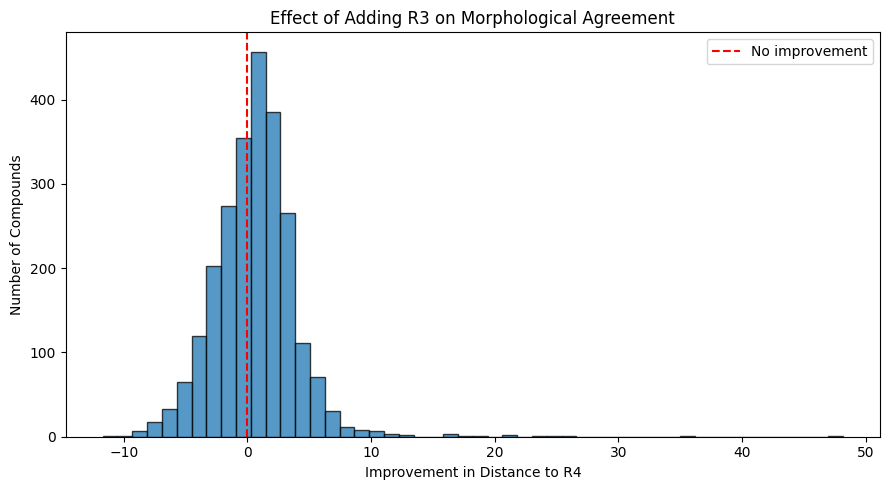

In [18]:
plt.figure(figsize=(9, 5))

plt.hist(
    df_improvement["Improvement"],
    bins=50,
    edgecolor="black",
    alpha=0.75
)

plt.axvline(
    x=0,
    color="red",
    linestyle="--",
    label="No improvement"
)

plt.xlabel("Improvement in Distance to R4")
plt.ylabel("Number of Compounds")
plt.title("Effect of Adding R3 on Morphological Agreement")
plt.legend()
plt.tight_layout()
plt.show()

Prepare final dataset for modeling.

In [19]:
# Combine our predictors with the regression outcome
# Improvement = distance(initial, R4) - distance(updated, R4)
# Positive values mean adding R3 moved the profile closer to R4
df_model = df_features.join(
    df_improvement[["Improvement"]]
)

print("Modeling dataset shape:", df_model.shape)

display(df_model.head())

print("\nOutcome distribution:")
display(df_model["Improvement"].describe())

Modeling dataset shape: (2437, 5)


,Mean_Object_Count,Min_Object_Count,Object_Count_Difference,Morphological_Disagreement,Improvement
Metadata_EOS,,,,,
EOS100001,515.0,330,370,66.555030,3.195025
EOS100002,806.0,608,396,46.927059,-3.671243
EOS100003,405.5,295,221,55.643160,1.995353
EOS100004,653.5,515,277,38.267200,-1.652142
EOS100005,786.5,716,141,51.766924,1.129304



Outcome distribution:


,Improvement
count,2437.000000
mean,0.584869
std,3.462647
min,-11.708977
25%,-1.368783
50%,0.660763
75%,2.350837
max,48.174716


In [20]:
# Hold out the test compounds with the same IDs as the split above
model_train = df_model.loc[train_ids]
model_test = df_model.loc[test_ids]

print("Train:", model_train.shape, "| Test:", model_test.shape)

print("\nImprovement (outcome) in train vs test:")
display(pd.DataFrame({
    "Train": model_train["Improvement"].describe(),
    "Test": model_test["Improvement"].describe()
}))

model_train.to_csv(OUTPUT / "model_train.csv")
model_test.to_csv(OUTPUT / "model_test.csv")

Train: (1949, 5) | Test: (488, 5)

Improvement (outcome) in train vs test:


,Train,Test
count,1949.000000,488.000000
mean,0.563716,0.669352
std,3.550124,3.090597
min,-11.708977,-8.653988
25%,-1.420576,-1.110859
50%,0.633751,0.828670
75%,2.310603,2.502128
max,48.174716,12.628700


In [21]:
# Save prepared replicate-level data
df_prepared.to_csv(
    OUTPUT / "df_prepared.csv",
    index=False
)

# Save the train/test compound IDs
pd.Series(
    train_ids,
    name="Metadata_EOS"
).to_csv(
    OUTPUT / "train_ids.csv",
    index=False
)

pd.Series(
    test_ids,
    name="Metadata_EOS"
).to_csv(
    OUTPUT / "test_ids.csv",
    index=False
)